In [36]:
from doctest import debug, debug_script
from hashlib import algorithms_available
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from skimage.restoration import unwrap_phase

# Point sys.path to the repository root
repo_root = Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [51]:

# Import the PhaseMapGenerator (assuming you saved it in src/phase_map_generator.py)
# from src.phase_map_generator import PhaseMapGenerator
import config
import src.phase_extraction as pe
import src.calibration as calib
import src.slit_analysis as sa

# 30 bar

# Phase extraction at 0 degrees

In [66]:
hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-30bar"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)


ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug = False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug = False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left_perp, x_right_perp = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_perp, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left_perp, x_right_perp, debug = False)
calibrated_phase_perp = unwrap_phase(calibrated_phase_perp)


Unsupported data type for _convert.
Unsupported data type for _convert.


In [67]:
# Constants
NOZZLE_WIDTH_MM = 6.0
NOZZLE_OPENING_MM = 0.5
px_to_mm = calib.calculate_px_to_mm(x_left_perp, x_right_perp, NOZZLE_WIDTH_MM)

# Phase extraction at 90 degrees

In [68]:

hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-30bar 90deg"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug = False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug = False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left_para, x_right_para = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_para, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left_para, x_right_para, debug = False)


Unsupported data type for _convert.
Unsupported data type for _convert.


# density calculation

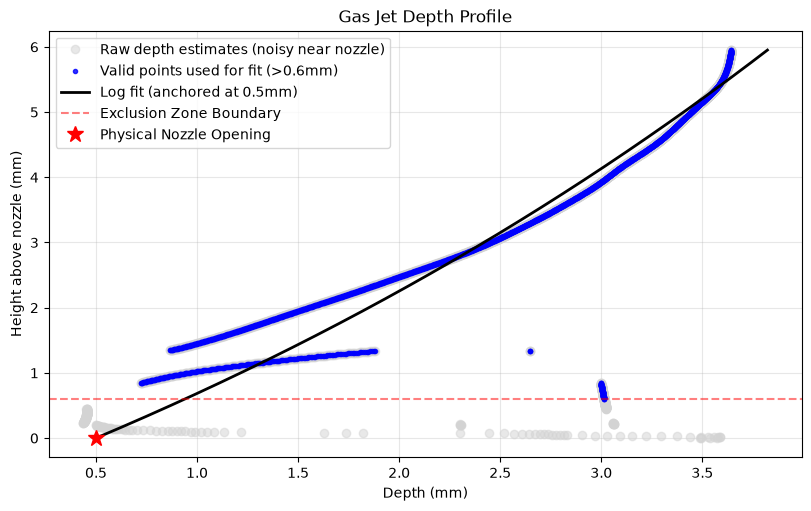

In [69]:
# Crop to 6mm and Flip (so y=0 is the nozzle edge)
phi_cropped = sa.crop_and_format_phase_map(
    calibrated_phase_para,
    nozzle_edge_y=ref_edge,
    px_to_mm=px_to_mm,
    max_height_mm=6.0
)

# Calculate Depth
y_mm_para, depth_fit_para, depth_debug = sa.estimate_depth_profile(
    phi_cropped,
    px_to_mm,
    nozzle_opening=NOZZLE_OPENING_MM,
    fit_type="log_constrained",
    exclude_y_mm=0.6,
    debug_show=True,

)

In [70]:
# Convert to Density
cropped_phase_to_density = sa.crop_and_format_phase_map(
    calibrated_phase_perp,
    nozzle_edge_y=ref_edge-50,
    px_to_mm=px_to_mm,
    max_height_mm=6.0)
density_map_30bar, x_mm, y_mm = sa.phase_to_density(cropped_phase_to_density, px_to_mm, depth_y_mm=y_mm_para, depth_profile_mm=depth_fit_para, gas="argon")

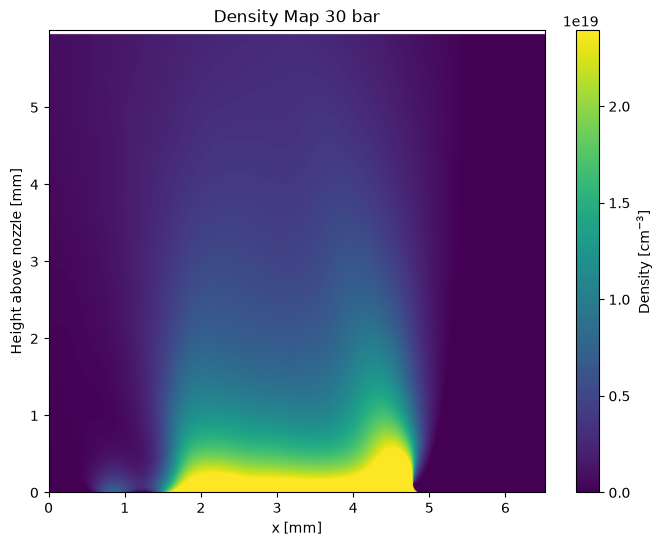

In [71]:

# Plot the result
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

m = np.nanpercentile(np.abs(density_map_30bar), 98.0)
extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

im = ax.imshow(density_map_30bar, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)

# Format title and axes for dark mode (force black text/ticks)
ax.set_title("Density Map 30 bar", color="black")
ax.set_xlabel("x [mm]", color="black")
ax.set_ylabel("Height above nozzle [mm]", color="black")
ax.tick_params(colors="black")

# Force plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

# Add and format the colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Density [cm$^{-3}$]", color="black")
cbar.ax.yaxis.set_tick_params(color="black") # Tick marks
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black') # Tick labels

plt.show()

Measured median Density at Exit:   3.64e+19 cm^-3
Theoretical De Laval Prediction: 4.33e+19 cm^-3
--------------------------------------------------
The 1D theoretical model overestimates the measured mean density by a factor of ~1.2x.


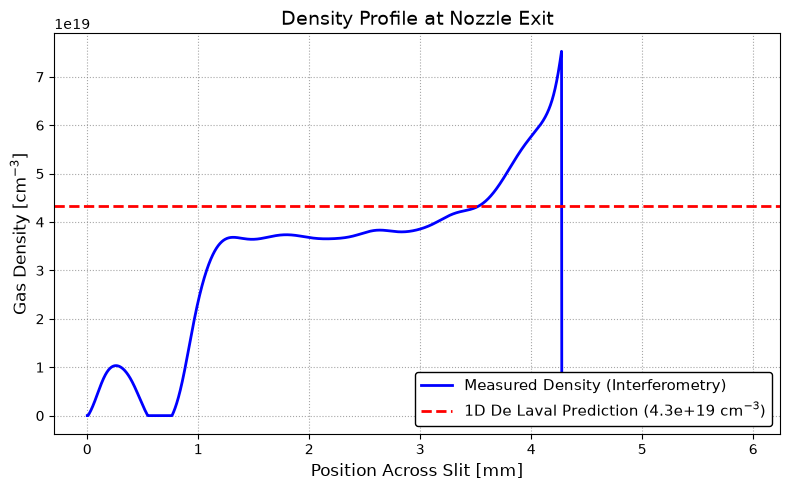

In [72]:

# Since 'density_map' is already cropped to the region above the nozzle,
# the exit corresponds to the 0th row.
edge_z_pixel = 0

# Extract the horizontal lineout across the nozzle opening (between x_left and x_right)
measured_exit_lineout_30bar = density_map_30bar[edge_z_pixel, int(x_left):int(x_right)]

# Find the median measured density right at the exit
measured_median_density = np.median(measured_exit_lineout_30bar)

# Theoretical baseline calculated from 1D De Laval isentropic flow (30 bar backing pressure)
theoretical_peak_density = 4.33e19 # cm^-3

# Calculate the discrepancy ratio
ratio = theoretical_peak_density / measured_median_density

print(f"Measured median Density at Exit:   {measured_median_density:.2e} cm^-3")
print(f"Theoretical De Laval Prediction: {theoretical_peak_density:.2e} cm^-3")
print("-" * 50)
print(f"The 1D theoretical model overestimates the measured mean density by a factor of ~{ratio:.1f}x.")

# --- Plotting ---
# Create an x-axis in millimeters based on your previously defined px_to_mm
x_axis_mm = np.arange(len(measured_exit_lineout_30bar)) * px_to_mm

# Explicitly set the figure background to white
fig, ax = plt.subplots(figsize=(8, 5), facecolor="white")
ax.set_facecolor("white")

# Plot the empirical measurement
ax.plot(x_axis_mm, measured_exit_lineout_30bar, label="Measured Density (Interferometry)", color="blue", linewidth=2)

# Plot the theoretical prediction as a constant threshold
ax.axhline(y=theoretical_peak_density, color="red", linestyle="--", linewidth=2,
            label=f"1D De Laval Prediction ({theoretical_peak_density:.1e} cm$^{{-3}}$)")

# Formatting - Forcing colors to black for dark mode IDEs
ax.set_title("Density Profile at Nozzle Exit", fontsize=14, color="black")
ax.set_xlabel("Position Across Slit [mm]", fontsize=12, color="black")
ax.set_ylabel("Gas Density [cm$^{-3}$]", fontsize=12, color="black")
ax.tick_params(colors="black")

# Force the plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

ax.grid(True, linestyle=":", alpha=0.7, color="gray")

# Place legend in the bottom right and force text to black
legend = ax.legend(loc="lower right", fontsize=11, facecolor="white", framealpha=1.0, edgecolor="black")
for text in legend.get_texts():
    text.set_color("black")

plt.tight_layout()
plt.show()

# 5 bar


In [73]:
hdf5_path_5bar = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-5bar"

# Using the same ROI defined earlier
ref_img_5, exp_img_5, ref_roi_5, exp_roi_5 = pe.get_interferometry_images(hdf5_path_5bar, roi=roi)

ref_fourier_shifted_5 = pe.get_fourier(ref_roi_5)
exp_fourier_shifted_5 = pe.get_fourier(exp_roi_5)

dominant_frequency_5 = pe.get_dominant_frequency(ref_fourier_shifted_5, debug=False)

delta_phase_wrapped_5 = pe.get_delta_phase_wrapped(ref_fourier_shifted_5, exp_fourier_shifted_5, dominant_frequency_5, debug=False)
ref_edge_5, *_ = calib.estimate_nozzle_edge(ref_roi_5)
x_left_5, x_right_5 = calib.detect_nozzle_x_range(ref_roi_5, ref_edge_5)
calibrated_phase_perp_5, _ = calib.calibrate_phase(delta_phase_wrapped_5, ref_edge_5, x_left_5, x_right_5, debug=False)
calibrated_phase_perp_5 = unwrap_phase(calibrated_phase_perp_5)



Unsupported data type for _convert.
Unsupported data type for _convert.


In [83]:

hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-5bar 90deg"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency,
                                                 debug=False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left_para, x_right_para = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_para, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left_para, x_right_para, debug=False)

# Crop to 6mm and Flip (so y=0 is the nozzle edge)
phi_cropped = sa.crop_and_format_phase_map(
    calibrated_phase_para,
    nozzle_edge_y=ref_edge,
    px_to_mm=px_to_mm,
    max_height_mm=6.0
)

# Calculate Depth
y_mm_para, depth_fit_para, depth_debug = sa.estimate_depth_profile(
    phi_cropped,
    px_to_mm,
    nozzle_opening=NOZZLE_OPENING_MM,
    fit_type="log_constrained",
    exclude_y_mm=0.6,
    debug_show=False,

)


Unsupported data type for _convert.
Unsupported data type for _convert.


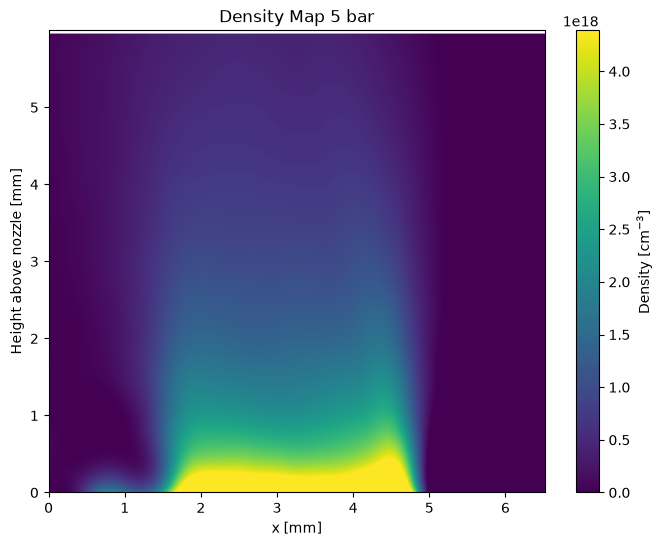

In [76]:
cropped_phase_to_density = sa.crop_and_format_phase_map(
    calibrated_phase_perp_5,
    nozzle_edge_y=ref_edge - 50,
    px_to_mm=px_to_mm,
    max_height_mm=6.0)
density_map_5bar, x_mm, y_mm = sa.phase_to_density(cropped_phase_to_density, px_to_mm, depth_y_mm=y_mm_para,
                                              depth_profile_mm=depth_fit_para, gas="argon")

# Plot the result
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

m = np.nanpercentile(np.abs(density_map_5bar), 98.0)
extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

im = ax.imshow(density_map_5bar, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)

# Format title and axes for dark mode (force black text/ticks)
ax.set_title("Density Map 5 bar", color="black")
ax.set_xlabel("x [mm]", color="black")
ax.set_ylabel("Height above nozzle [mm]", color="black")
ax.tick_params(colors="black")

# Force plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

# Add and format the colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Density [cm$^{-3}$]", color="black")
cbar.ax.yaxis.set_tick_params(color="black")  # Tick marks
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black')  # Tick labels

measured_exit_lineout_5bar = density_map_5bar[edge_z_pixel, int(x_left):int(x_right)]



# 10 bar

In [78]:
hdf5_path10bar = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-10bar"

# Using the same ROI defined earlier
ref_img_10, exp_img_10, ref_roi_10, exp_roi_10 = pe.get_interferometry_images(hdf5_path10bar, roi=roi)

ref_fourier_shifted_10 = pe.get_fourier(ref_roi_10)
exp_fourier_shifted_10 = pe.get_fourier(exp_roi_10)

dominant_frequency_10 = pe.get_dominant_frequency(ref_fourier_shifted_10, debug=False)

delta_phase_wrapped_10 = pe.get_delta_phase_wrapped(ref_fourier_shifted_10, exp_fourier_shifted_10, dominant_frequency_10,
                                                   debug=False)

ref_edge_10, *_ = calib.estimate_nozzle_edge(ref_roi_10)
x_left_10, x_right_10 = calib.detect_nozzle_x_range(ref_roi_10, ref_edge_10)
calibrated_phase_perp_10, _ = calib.calibrate_phase(delta_phase_wrapped_10, ref_edge_10, x_left_10, x_right_10, debug=False)
calibrated_phase_perp_10 = unwrap_phase(calibrated_phase_perp_10)

Unsupported data type for _convert.
Unsupported data type for _convert.


In [82]:

hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-10bar 90deg"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency,
                                                 debug=False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left_para, x_right_para = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_para, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left_para, x_right_para, debug=False)

Unsupported data type for _convert.
Unsupported data type for _convert.


In [84]:

# Crop to 6mm and Flip (so y=0 is the nozzle edge)
phi_cropped = sa.crop_and_format_phase_map(
    calibrated_phase_para,
    nozzle_edge_y=ref_edge,
    px_to_mm=px_to_mm,
    max_height_mm=6.0
)

# Calculate Depth
y_mm_para, depth_fit_para, depth_debug = sa.estimate_depth_profile(
    phi_cropped,
    px_to_mm,
    nozzle_opening=NOZZLE_OPENING_MM,
    fit_type="log_constrained",
    exclude_y_mm=0.6,
    debug_show=False,

)

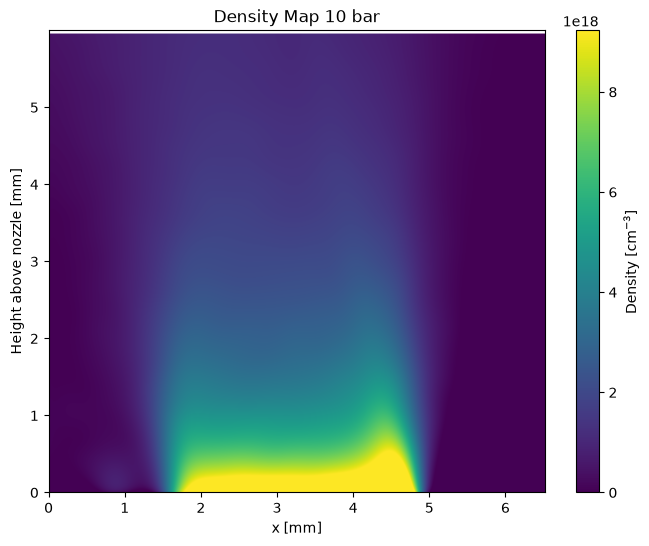

In [85]:

cropped_phase_to_density = sa.crop_and_format_phase_map(
    calibrated_phase_perp_10,
    nozzle_edge_y=ref_edge - 50,
    px_to_mm=px_to_mm,
    max_height_mm=6.0)
density_map_10bar, x_mm, y_mm = sa.phase_to_density(cropped_phase_to_density, px_to_mm, depth_y_mm=y_mm_para,
                                                    depth_profile_mm=depth_fit_para, gas="argon")

# Plot the result
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

m = np.nanpercentile(np.abs(density_map_10bar), 98.0)
extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

im = ax.imshow(density_map_10bar, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)

# Format title and axes for dark mode (force black text/ticks)
ax.set_title("Density Map 10 bar", color="black")
ax.set_xlabel("x [mm]", color="black")
ax.set_ylabel("Height above nozzle [mm]", color="black")
ax.tick_params(colors="black")

# Force plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

# Add and format the colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Density [cm$^{-3}$]", color="black")
cbar.ax.yaxis.set_tick_params(color="black")  # Tick marks
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black')  # Tick labels

measured_exit_lineout_10bar = density_map_10bar[edge_z_pixel, int(x_left):int(x_right)]


# 15 bar

In [88]:
hdf5_path_15bar = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-15bar"

# Using the same ROI defined earlier
ref_img_15bar, exp_img_15bar, ref_roi_15bar, exp_roi_15bar = pe.get_interferometry_images(hdf5_path_15bar, roi=roi)

ref_fourier_shifted_15bar = pe.get_fourier(ref_roi_15bar)
exp_fourier_shifted_15bar = pe.get_fourier(exp_roi_15bar)

dominant_frequency_15bar = pe.get_dominant_frequency(ref_fourier_shifted_15bar, debug=False)

delta_phase_wrapped_15bar = pe.get_delta_phase_wrapped(ref_fourier_shifted_15bar, exp_fourier_shifted_15bar, dominant_frequency_15bar,
                                                      debug=False)
ref_edge_15bar, *_ = calib.estimate_nozzle_edge(ref_roi_15bar)
x_left_15bar, x_right_15bar = calib.detect_nozzle_x_range(ref_roi_15bar, ref_edge_15bar)
calibrated_phase_perp_15bar, _ = calib.calibrate_phase(delta_phase_wrapped_15bar, ref_edge_15bar, x_left_15bar, x_right_15bar, debug=False)
calibrated_phase_perp_15bar = unwrap_phase(calibrated_phase_perp_15bar)

Unsupported data type for _convert.
Unsupported data type for _convert.


In [97]:

hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-15bar 90deg"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency,
                                                 debug=False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left_para, x_right_para = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_para, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left_para, x_right_para, debug=False)


# Crop to 6mm and Flip (so y=0 is the nozzle edge)
phi_cropped = sa.crop_and_format_phase_map(
    calibrated_phase_para,
    nozzle_edge_y=ref_edge,
    px_to_mm=px_to_mm,
    max_height_mm=6.0
)

# Calculate Depth
y_mm_para, depth_fit_para, depth_debug = sa.estimate_depth_profile(
    phi_cropped,
    px_to_mm,
    nozzle_opening=NOZZLE_OPENING_MM,
    fit_type="log_constrained",
    exclude_y_mm=0.6,
    debug_show=False,

)



Unsupported data type for _convert.
Unsupported data type for _convert.


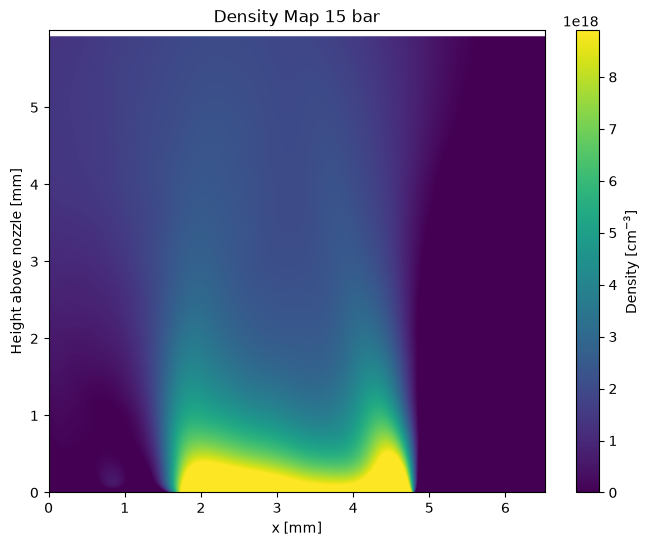

In [95]:

cropped_phase_to_density = sa.crop_and_format_phase_map(
    calibrated_phase_perp_15bar,
    nozzle_edge_y=ref_edge - 50,
    px_to_mm=px_to_mm,
    max_height_mm=6.0)
density_map_15bar, x_mm, y_mm = sa.phase_to_density(cropped_phase_to_density, px_to_mm, depth_y_mm=y_mm_para,
                                                    depth_profile_mm=depth_fit_para, gas="argon")

# Plot the result
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

m = np.nanpercentile(np.abs(density_map_15bar), 98.0)
extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

im = ax.imshow(density_map_15bar, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)

# Format title and axes for dark mode (force black text/ticks)
ax.set_title("Density Map 15 bar", color="black")
ax.set_xlabel("x [mm]", color="black")
ax.set_ylabel("Height above nozzle [mm]", color="black")
ax.tick_params(colors="black")

# Force plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

# Add and format the colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Density [cm$^{-3}$]", color="black")
cbar.ax.yaxis.set_tick_params(color="black")  # Tick marks
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black')  # Tick labels

measured_exit_lineout_15bar = density_map_15bar[edge_z_pixel, int(x_left):int(x_right)]


# 20 bar

In [112]:
hdf5_path_20bar = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-20bar"

# Using the same ROI defined earlier
ref_img_20bar, exp_img_20bar, ref_roi_20bar, exp_roi_20bar = pe.get_interferometry_images(hdf5_path_20bar, roi=roi)

ref_fourier_shifted_20bar = pe.get_fourier(ref_roi_20bar)
exp_fourier_shifted_20bar = pe.get_fourier(exp_roi_20bar)

dominant_frequency_20bar = pe.get_dominant_frequency(ref_fourier_shifted_20bar, debug=False)

delta_phase_wrapped_20bar = pe.get_delta_phase_wrapped(ref_fourier_shifted_20bar, exp_fourier_shifted_20bar, dominant_frequency_20bar,
                                                      debug=False)
ref_edge_20bar, *_ = calib.estimate_nozzle_edge(ref_roi_20bar)
x_left_20bar, x_right_20bar = calib.detect_nozzle_x_range(ref_roi_20bar, ref_edge_20bar)
calibrated_phase_perp_20bar, _ = calib.calibrate_phase(delta_phase_wrapped_20bar, ref_edge_20bar, x_left_20bar, x_right_20bar, debug=False)
calibrated_phase_perp_20bar = unwrap_phase(calibrated_phase_perp_20bar)

Unsupported data type for _convert.
Unsupported data type for _convert.


In [113]:

hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-20bar 90deg"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency,
                                                 debug=False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left_para, x_right_para = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_para, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left_para, x_right_para, debug=False)


# Crop to 6mm and Flip (so y=0 is the nozzle edge)
phi_cropped = sa.crop_and_format_phase_map(
    calibrated_phase_para,
    nozzle_edge_y=ref_edge,
    px_to_mm=px_to_mm,
    max_height_mm=6.0
)

# Calculate Depth
y_mm_para, depth_fit_para, depth_debug = sa.estimate_depth_profile(
    phi_cropped,
    px_to_mm,
    nozzle_opening=NOZZLE_OPENING_MM,
    fit_type="log_constrained",
    exclude_y_mm=0.6,
    debug_show=False,
)



Unsupported data type for _convert.
Unsupported data type for _convert.


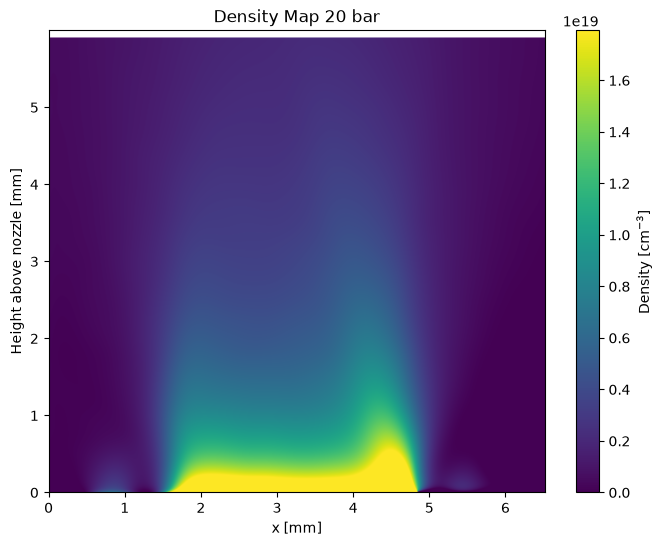

In [114]:

cropped_phase_to_density = sa.crop_and_format_phase_map(
    calibrated_phase_perp_20bar,
    nozzle_edge_y=ref_edge - 50,
    px_to_mm=px_to_mm,
    max_height_mm=6.0)
density_map_20bar, x_mm, y_mm = sa.phase_to_density(cropped_phase_to_density, px_to_mm, depth_y_mm=y_mm_para,
                                                    depth_profile_mm=depth_fit_para, gas="argon")

# Plot the result
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

m = np.nanpercentile(np.abs(density_map_20bar), 98.0)
extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

im = ax.imshow(density_map_20bar, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)

# Format title and axes for dark mode (force black text/ticks)
ax.set_title("Density Map 20 bar", color="black")
ax.set_xlabel("x [mm]", color="black")
ax.set_ylabel("Height above nozzle [mm]", color="black")
ax.tick_params(colors="black")

# Force plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

# Add and format the colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Density [cm$^{-3}$]", color="black")
cbar.ax.yaxis.set_tick_params(color="black")  # Tick marks
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black')  # Tick labels

measured_exit_lineout_20bar = density_map_20bar[edge_z_pixel, int(x_left):int(x_right)]


# 25 bar

Unsupported data type for _convert.
Unsupported data type for _convert.


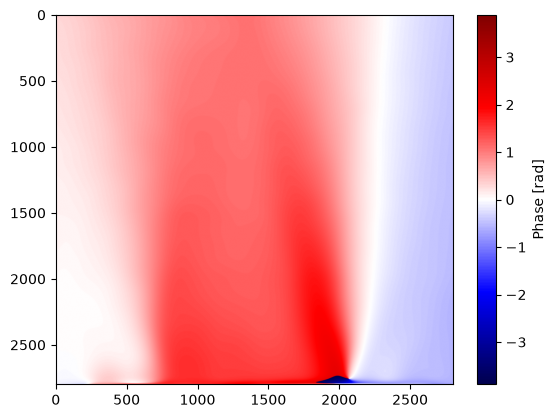

In [118]:
hdf5_path_25bar = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-25bar"

# Using the same ROI defined earlier
ref_img_25bar, exp_img_25bar, ref_roi_25bar, exp_roi_25bar = pe.get_interferometry_images(hdf5_path_25bar, roi=roi)

ref_fourier_shifted_25bar = pe.get_fourier(ref_roi_25bar)
exp_fourier_shifted_25bar = pe.get_fourier(exp_roi_25bar)

dominant_frequency_25bar = pe.get_dominant_frequency(ref_fourier_shifted_25bar, debug=False)

delta_phase_wrapped_25bar = pe.get_delta_phase_wrapped(ref_fourier_shifted_25bar, exp_fourier_shifted_25bar, dominant_frequency_25bar,
                                                      debug=False)
ref_edge_25bar, *_ = calib.estimate_nozzle_edge(ref_roi_25bar)
x_left_25bar, x_right_25bar = calib.detect_nozzle_x_range(ref_roi_25bar, ref_edge_25bar)
calibrated_phase_perp_25bar, _ = calib.calibrate_phase(delta_phase_wrapped_25bar, ref_edge_25bar, x_left_25bar, x_right_25bar, debug=True)
calibrated_phase_perp_25bar = unwrap_phase(calibrated_phase_perp_25bar)

In [119]:
hdf5_path = r"C:\Users\vmlab\Documents\data\files\2026\03\25\Ar-25bar 90deg"

roi = [2000, 5000, 1000, 4000]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)

dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(ref_fourier_shifted, exp_fourier_shifted, dominant_frequency,
                                                 debug=False)
ref_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left_para, x_right_para = calib.detect_nozzle_x_range(ref_roi, ref_edge)
calibrated_phase_para, _ = calib.calibrate_phase(delta_phase_wrapped, ref_edge, x_left_para, x_right_para, debug=False)


# Crop to 6mm and Flip (so y=0 is the nozzle edge)
phi_cropped = sa.crop_and_format_phase_map(
    calibrated_phase_para,
    nozzle_edge_y=ref_edge,
    px_to_mm=px_to_mm,
    max_height_mm=6.0
)

# Calculate Depth
y_mm_para, depth_fit_para, depth_debug = sa.estimate_depth_profile(
    phi_cropped,
    px_to_mm,
    nozzle_opening=NOZZLE_OPENING_MM,
    fit_type="log_constrained",
    exclude_y_mm=0.6,
    debug_show=False,
)



Unsupported data type for _convert.
Unsupported data type for _convert.


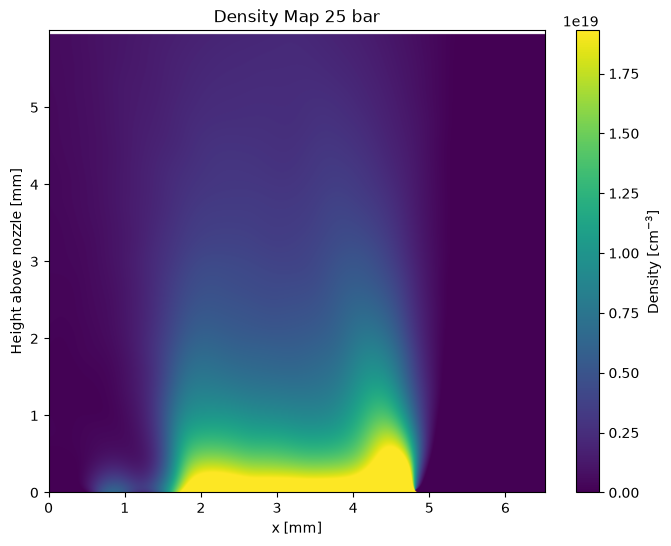

In [120]:

cropped_phase_to_density = sa.crop_and_format_phase_map(
    calibrated_phase_perp_25bar,
    nozzle_edge_y=ref_edge - 50,
    px_to_mm=px_to_mm,
    max_height_mm=6.0)
density_map_25bar, x_mm, y_mm = sa.phase_to_density(cropped_phase_to_density, px_to_mm, depth_y_mm=y_mm_para,
                                                    depth_profile_mm=depth_fit_para, gas="argon")

# Plot the result
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
ax.set_facecolor("white")

m = np.nanpercentile(np.abs(density_map_25bar), 98.0)
extent = [x_mm[0], x_mm[-1], y_mm[0], y_mm[-1]]

im = ax.imshow(density_map_25bar, origin="lower", extent=extent, aspect="auto", cmap="viridis", vmin=0.0, vmax=m)

# Format title and axes for dark mode (force black text/ticks)
ax.set_title("Density Map 25 bar", color="black")
ax.set_xlabel("x [mm]", color="black")
ax.set_ylabel("Height above nozzle [mm]", color="black")
ax.tick_params(colors="black")

# Force plot borders (spines) to be black
for spine in ax.spines.values():
    spine.set_color("black")

# Add and format the colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Density [cm$^{-3}$]", color="black")
cbar.ax.yaxis.set_tick_params(color="black")  # Tick marks
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='black')  # Tick labels

measured_exit_lineout_25bar = density_map_25bar[edge_z_pixel, int(x_left):int(x_right)]
